# Assignment 2: Image Classification, Transfer Learning, and Style Robustness in PyTorch

In this assignment you will:

- Load an image classification dataset from Hugging Face (`"JamieSJS/imagenet-10"`).
- Build a preprocessing pipeline for images.
- Wrap the data in PyTorch `Dataset` and `DataLoader` objects.
- Define and train a custom CNN classifier from scratch.
- Track metrics such as loss, accuracy, and macro F1.
- Use a pretrained CNN (e.g. ResNet18) for transfer learning.
- Create a style-modified version of the dataset and test robustness.
- Compare the behavior of the classifiers to a pretrained object detector on the same image.

Cells marked with `# === TODO ===` require your code.


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader
from datasets import load_dataset

import numpy as np
import random
import matplotlib.pyplot as plt

from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

import torchvision.transforms as T
import torchvision.models as models

from PIL import Image
from collections import Counter

# Reproducibility helpers
def set_seed(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)

# Use GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cuda')

## 1. Dataset loading and basic exploration

Use Hugging Face Datasets to load `"JamieSJS/imagenet-10"` and understand its structure.


In [ ]:
# === TODO ===
# Load the dataset and quickly inspect it.
# Look at the available splits and a single example.

dataset = load_dataset("JamieSJS/imagenet-10")
print(dataset)
print(dataset["test"][0])



/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md:   0%|          | 0.00/229 [00:00<?, ?B/s]

test.parquet:   0%|          | 0.00/116M [00:00<?, ?B/s]

Generating test split:   0%|          | 0/13000 [00:00<?, ? examples/s]

DatasetDict({
    test: Dataset({
        features: ['image', 'label'],
        num_rows: 13000
    })
})
{'image': <PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=224x224 at 0x7C4CA4511220>, 'label': 0}


### 1.1 Basic dataset exploration

Tasks:
- Identify the image and label column names.
- Extract the list of class names if available (if not provided, we will just use numeric labels 0..9).
- Compute the number of images per class in the full dataset.
- Visualize a small batch of images with their labels.


In [ ]:
image_key = "image"
label_key = "label"
# For imagenet-10, there are typically 10 classes (0-9).
# We explicitly set this value based on the dataset name to avoid potential
# issues if a specific split (e.g., 'test') happens to be missing one of the classes.
num_label_values = 11
label_names = [f"class_{i}" for i in range(num_label_values)]
print(label_names)

['class_0', 'class_1', 'class_2', 'class_3', 'class_4', 'class_5', 'class_6', 'class_7', 'class_8', 'class_9', 'class_10']


Dear Hassan, in the upper cell, as was mentioned, class_9 inexistant in the data, I added the class label names to 11 to get one higher while keeping the total number of classes to 10, I thought it doesn't matter what are the classes names as long as they're 10 and containing needed data. So I put num_label_values = 11 instead of 10 and got (as shown below) 10 classes each with 1300 samples.

In [ ]:
# === TODO ===
# Compute and print the number of examples per class in the full dataset.

full_split = dataset["test"]
full_labels = [example[label_key] for example in full_split]
label_counts = Counter(full_labels)

for idx, count in sorted(label_counts.items()):
    print(f"Class {idx} ({label_names[idx]}): {count} samples")

Class 0 (class_0): 1300 samples
Class 1 (class_1): 1300 samples
Class 2 (class_2): 1300 samples
Class 3 (class_3): 1300 samples
Class 4 (class_4): 1300 samples
Class 5 (class_5): 1300 samples
Class 6 (class_6): 1300 samples
Class 7 (class_7): 1300 samples
Class 8 (class_8): 1300 samples
Class 10 (class_10): 1300 samples


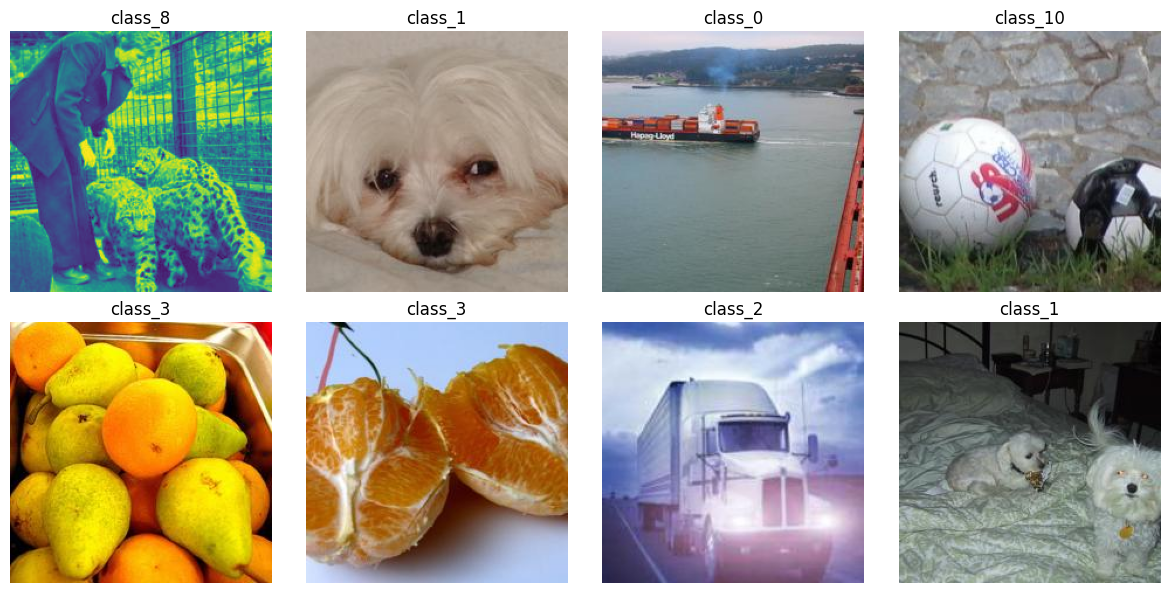

In [ ]:
# Visualize a few random images with their labels.

num_examples_to_show = 8
indices = random.sample(range(len(full_split)), num_examples_to_show)

plt.figure(figsize=(12, 6))
for i, idx in enumerate(indices):
    example = full_split[idx]
    img = example[image_key]
    label = example[label_key]

    plt.subplot(2, 4, i + 1)
    plt.imshow(img)
    plt.axis("off")
    plt.title(label_names[label])
plt.tight_layout()
plt.show()

## 2. Splits, preprocessing, and DataLoaders

Create train / validation / test splits, define image transforms, and
wrap everything in PyTorch Datasets and DataLoaders.


In [ ]:
# === TODO ===
# Create train/val/test splits from the single provided split.
# First split: full -> train (70%) + temp (30%)
# Second split: temp -> val (15%) + test (15%)

full_dataset = dataset["test"]

# First split: full -> train (70%) + temp (30%)
split_1 = full_dataset.train_test_split(test_size=0.3, seed=42)
train_hf = split_1["train"]
temp_hf = split_1["test"]

# Second split: temp -> val (15%) + test (15%) (temp is 30% of original, so split 50/50)
split_2 = temp_hf.train_test_split(test_size=0.5, seed=42)
val_hf = split_2["train"]
test_hf = split_2["test"]

len(train_hf), len(val_hf), len(test_hf)

(9100, 1950, 1950)

In [ ]:
image_size = 224  # images in this dataset are 224x224

imagenet_mean = [0.485, 0.456, 0.406]
imagenet_std  = [0.229, 0.224, 0.225]

train_transform = T.Compose([
    T.Resize((image_size, image_size)), # resize to 224x224
    T.RandomHorizontalFlip(p=0.5), # 50% chance of horizontal flip
    T.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.1), # color jitter
    T.ToTensor(), # convert to tensor
    T.Normalize(mean=imagenet_mean, std=imagenet_std), # normalize
])

test_transform = T.Compose([
    T.Resize((image_size, image_size)), # resize
    T.ToTensor(), # convert to tensor
    T.Normalize(mean=imagenet_mean, std=imagenet_std), # normalize
])

In [ ]:
# === TODO ===
# Implement a Dataset that wraps a Hugging Face split.
# It should return (image_tensor, label) when indexed.
# Make sure the image is converted to RGB before applying transforms.

class HFImageDataset(Dataset):
    def __init__(self, hf_dataset, image_key, label_key, transform=None):
        self.ds = hf_dataset
        self.image_key = image_key
        self.label_key = label_key
        self.transform = transform

    def __len__(self):
        return len(self.ds)

    def __getitem__(self, idx):
        example = self.ds[idx]
        img = example[self.image_key]
        label = example[self.label_key]

        # Ensure 3-channel RGB
        if img.mode != "RGB":
            img = img.convert("RGB")

        if self.transform is not None:
            img = self.transform(img)

        return img, label

train_dataset = HFImageDataset(train_hf, image_key, label_key, transform=train_transform)
val_dataset   = HFImageDataset(val_hf, image_key, label_key, transform=test_transform)
test_dataset  = HFImageDataset(test_hf, image_key, label_key, transform=test_transform)

len(train_dataset), len(val_dataset), len(test_dataset)

(9100, 1950, 1950)

In [ ]:
# === TODO ===
# Create DataLoaders for the three datasets.
# A reasonable batch size is around 32; shuffle only the training loader.

batch_size = 32  # 224x224 images, so a moderate batch size

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader   = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_loader  = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

len(train_loader), len(val_loader), len(test_loader)

(285, 61, 61)

## 3. Custom CNN classifier (from scratch)

Define a small convolutional neural network:

- A feature extractor with several convolutional blocks.
- A classifier head with fully connected layers.
- Output logits of shape `[batch_size, num_classes]`.

Use `CrossEntropyLoss` for loss


In [ ]:
# === TODO ===
# Implement a SimpleCNN model suitable for this dataset.
# You can follow the structure from the lecture and adapt it.

num_classes = num_label_values # Use the dynamically determined number of classes

class SimpleCNN(nn.Module):
    def __init__(self, num_classes: int):
        super().__init__()
        self.features = nn.Sequential(
            # Block 1
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2), # Output: 16 channels, 112x112

            # Block 2
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2), # Output: 32 channels, 56x56

            # Block 3
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2), # Output: 64 channels, 28x28

            # Block 4
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)  # Output: 128 channels, 14x14
        )

        # Compute flattened size dynamically
        with torch.no_grad():
            dummy = torch.zeros(1, 3, image_size, image_size)
            out = self.features(dummy)
            flattened_dim = out.view(1, -1).shape[1]

        self.classifier = nn.Sequential(
            nn.Linear(flattened_dim, 512),
            nn.ReLU(),
            nn.Dropout(0.5), # Add dropout for regularization
            nn.Linear(512, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = torch.flatten(x, 1) # Flatten all dimensions except batch
        x = self.classifier(x)
        return x

# Create a model and move it to the device
model_scratch = SimpleCNN(num_classes).to(device)

# Create a loss function (CrossEntropyLoss) and an optimizer (e.g. Adam)
# for model_scratch.
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model_scratch.parameters(), lr=0.001)

Elias: in the above cell, I switched the first line of code from num_classes = len(label_names) to num_label_values intentionally to cover all unexpected classes numbers.

Then below in the coding of the cnn architecture, will being aware of using the lines - way used in the lecture videos; I wanted to try something new, un condensed, a bit longer yes but for the sake of details and clarity and new initiatives


## 4. Training utilities: train_one_epoch and evaluate

Similar to Assignment 1, implement:

- `train_one_epoch(model, dataloader, optimizer, criterion, device)`
- `evaluate(model, dataloader, criterion, device)`

For each epoch, we track:
- loss
- accuracy
- macro F1 (to handle potential imbalance)


In [ ]:
# === TODO ===
# Implement train_one_epoch(model, dataloader, optimizer, criterion, device).
# It should loop over the dataloader, perform forward + backward passes,
# and return the average loss and accuracy for the epoch.

def train_one_epoch(model, dataloader, optimizer, criterion, device):
    model.train()
    running_loss = 0.0
    all_preds = []
    all_targets = []

    for X_batch, y_batch in dataloader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)

        optimizer.zero_grad()
        logits = model(X_batch)
        loss = criterion(logits, y_batch)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * X_batch.size(0)

        preds = torch.argmax(logits, dim=1)
        all_preds.extend(preds.detach().cpu().numpy())
        all_targets.extend(y_batch.detach().cpu().numpy())

    epoch_loss = running_loss / len(dataloader.dataset)
    epoch_acc = accuracy_score(all_targets, all_preds)
    return epoch_loss, epoch_acc

def evaluate(model, dataloader, criterion, device):
    model.eval()
    running_loss = 0.0
    all_preds = []
    all_targets = []

    with torch.no_grad():
        for X_batch, y_batch in dataloader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)

            logits = model(X_batch)
            loss = criterion(logits, y_batch)

            running_loss += loss.item() * X_batch.size(0)

            preds = torch.argmax(logits, dim=1)
            all_preds.extend(preds.detach().cpu().numpy())
            all_targets.extend(y_batch.detach().cpu().numpy())

    epoch_loss = running_loss / len(dataloader.dataset)
    epoch_acc = accuracy_score(all_targets, all_preds)
    macro_f1 = f1_score(all_targets, all_preds, average='macro')
    return epoch_loss, epoch_acc, macro_f1

## 5. Training the custom CNN

Train the scratch CNN model for several epochs and track:

- train_loss, val_loss
- train_acc, val_acc
- val_macro_f1

Then plot the curves.


In [ ]:
# === TODO ===
# Write the training loop for model_scratch.
# For each epoch:
# - train on the training set
# - evaluate on the validation set
# - store losses and accuracies for plotting

num_epochs = 8  # adjust as needed depending on training time

train_losses = []
val_losses = []
train_accs = []
val_accs = []
val_f1s = []

for epoch in range(num_epochs):
    train_loss, train_acc = train_one_epoch(model_scratch, train_loader, optimizer, criterion, device)
    val_loss, val_acc, val_f1 = evaluate(model_scratch, val_loader, criterion, device)

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accs.append(train_acc)
    val_accs.append(val_acc)
    val_f1s.append(val_f1)

    print(
        f"Epoch {epoch+1}/{num_epochs} "
        f"- Train loss: {train_loss:.4f}, Train acc: {train_acc:.4f} "
        f"- Val loss: {val_loss:.4f}, Val acc: {val_acc:.4f}, Val F1: {val_f1:.4f}"
    )


Epoch 1/8 - Train loss: 2.5719, Train acc: 0.2620 - Val loss: 1.5627, Val acc: 0.4390, Val F1: 0.3897
Epoch 2/8 - Train loss: 1.7641, Train acc: 0.3601 - Val loss: 1.7430, Val acc: 0.3862, Val F1: 0.3494
Epoch 3/8 - Train loss: 1.6205, Train acc: 0.4058 - Val loss: 1.2672, Val acc: 0.5364, Val F1: 0.5021
Epoch 4/8 - Train loss: 1.5366, Train acc: 0.4338 - Val loss: 1.2182, Val acc: 0.5564, Val F1: 0.5317
Epoch 5/8 - Train loss: 1.4812, Train acc: 0.4492 - Val loss: 1.2035, Val acc: 0.6041, Val F1: 0.6098
Epoch 6/8 - Train loss: 1.4404, Train acc: 0.4630 - Val loss: 1.1203, Val acc: 0.6215, Val F1: 0.6163
Epoch 7/8 - Train loss: 1.3942, Train acc: 0.4890 - Val loss: 1.1539, Val acc: 0.5959, Val F1: 0.5809
Epoch 8/8 - Train loss: 1.3593, Train acc: 0.5115 - Val loss: 1.0216, Val acc: 0.6810, Val F1: 0.6851


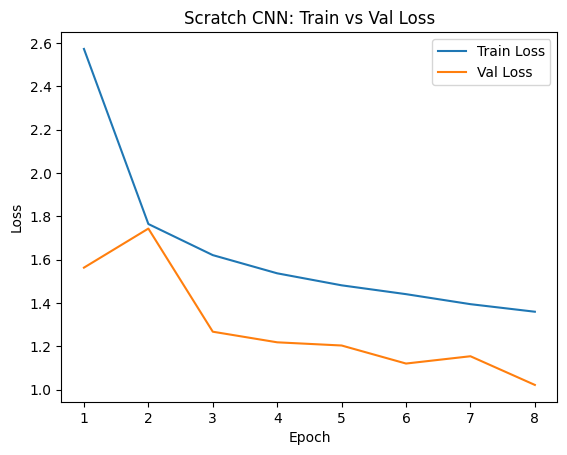

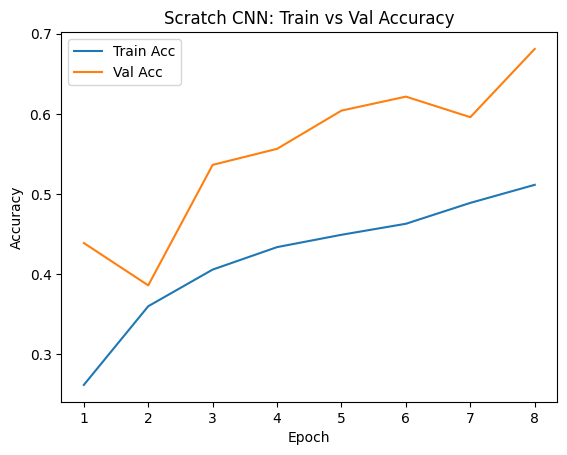

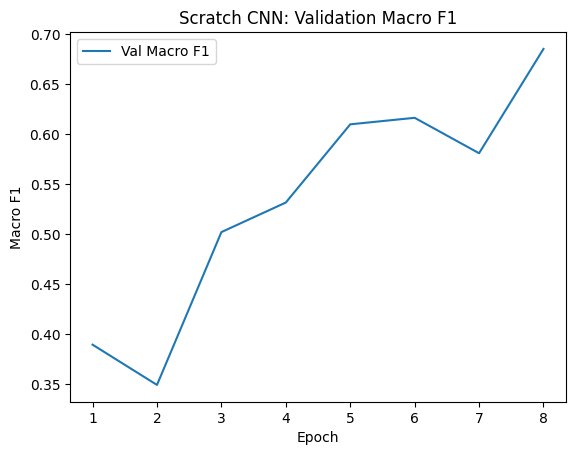

In [ ]:
# Plot the training vs validation loss, and training vs validation accuracy,

epochs = range(1, num_epochs + 1)

plt.figure()
plt.plot(epochs, train_losses, label="Train Loss")
plt.plot(epochs, val_losses, label="Val Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.title("Scratch CNN: Train vs Val Loss")
plt.show()

plt.figure()
plt.plot(epochs, train_accs, label="Train Acc")
plt.plot(epochs, val_accs, label="Val Acc")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.title("Scratch CNN: Train vs Val Accuracy")
plt.show()

plt.figure()
plt.plot(epochs, val_f1s, label="Val Macro F1")
plt.xlabel("Epoch")
plt.ylabel("Macro F1")
plt.legend()
plt.title("Scratch CNN: Validation Macro F1")
plt.show()


## 6. Final evaluation on the test set (scratch model)

Use the trained model and evaluate on the test set:

- Test loss
- Test accuracy
- Test macro F1
- Confusion matrix


In [ ]:
# === TODO ===
# Evaluate model_scratch on test_loader and print:
# - test loss
# - test accuracy
# - test macro F1

test_loss_scratch, test_acc_scratch, test_f1_scratch = evaluate(model_scratch, test_loader, criterion, device)

print(f"[Scratch CNN] Test Loss: {test_loss_scratch:.4f}")
print(f"[Scratch CNN] Test Acc:  {test_acc_scratch:.4f}")
print(f"[Scratch CNN] Test F1:   {test_f1_scratch:.4f}")

[Scratch CNN] Test Loss: 1.0177
[Scratch CNN] Test Acc:  0.6728
[Scratch CNN] Test F1:   0.6757


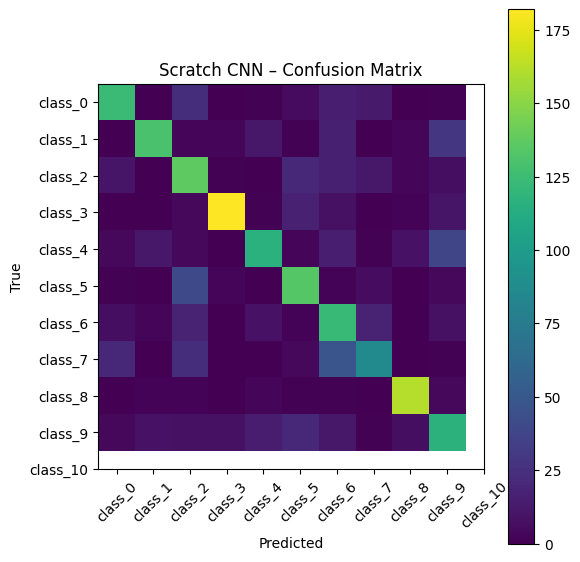

In [ ]:
# === TODO ===
# Build and display a confusion matrix for the scratch CNN on the test set.

model_scratch.eval()
all_preds = []
all_targets = []

with torch.no_grad():
    for X_batch, y_batch in test_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        logits = model_scratch(X_batch)
        preds = torch.argmax(logits, dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_targets.extend(y_batch.cpu().numpy())

cm_scratch = confusion_matrix(all_targets, all_preds)

plt.figure(figsize=(6, 6))
plt.imshow(cm_scratch, interpolation="nearest")
plt.title("Scratch CNN – Confusion Matrix")
plt.colorbar()
tick_marks = np.arange(num_classes)
plt.xticks(tick_marks, label_names, rotation=45)
plt.yticks(tick_marks, label_names)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.tight_layout()
plt.show()

## 7. Transfer learning with a pretrained model

Now we:

- Load a pretrained ResNet18.
- Replace the final FC layer with a new one for our `num_classes`.
- Optionally freeze the feature extractor so only the head trains.
- Train for a few epochs and evaluate.


Elias: after research I understood that we import a pretrained dataset, to gain more robustness for our model, more 'experience, to use it when dealing on new unseen data, and hopefully be greater in inference.

In [ ]:
# === TODO ===
# 1. Load a pretrained ResNet18 from torchvision.
# 2. Replace the final fully connected layer so that it has num_classes outputs.
# 3. Optionally freeze all layers except the last one.
# 4. Move the model to the chosen device.
# 5. Define its loss function and optimizer.


weights = models.ResNet18_Weights.DEFAULT
model_pretrained = models.resnet18(weights=weights)

# Replace the final layer
in_features = model_pretrained.fc.in_features
model_pretrained.fc = nn.Linear(in_features, num_classes)

# Optional: freeze feature extractor, only train the head
for name, param in model_pretrained.named_parameters():
    if not name.startswith("fc."):
        param.requires_grad = False

# Move to device
model_pretrained = model_pretrained.to(device)

criterion_pre = nn.CrossEntropyLoss()
optimizer_pre = optim.Adam(model_pretrained.parameters(), lr=0.001)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 216MB/s]


In [ ]:
num_epochs_pre = 5

train_losses_pre = []
val_losses_pre = []
train_accs_pre = []
val_accs_pre = []
val_f1s_pre = []

for epoch in range(num_epochs_pre):
    train_loss, train_acc = train_one_epoch(model_pretrained, train_loader, optimizer_pre, criterion_pre, device)
    val_loss, val_acc, val_f1 = evaluate(model_pretrained, val_loader, criterion_pre, device)

    train_losses_pre.append(train_loss)
    val_losses_pre.append(val_loss)
    train_accs_pre.append(train_acc)
    val_accs_pre.append(val_acc)
    val_f1s_pre.append(val_f1)

    print(
        f"[Pretrained] Epoch {epoch+1}/{num_epochs_pre} "
        f"- Train loss: {train_loss:.4f}, Train acc: {train_acc:.4f} "
        f"- Val loss: {val_loss:.4f}, Val acc: {val_acc:.4f}, Val F1: {val_f1:.4f}"
    )


[Pretrained] Epoch 1/5 - Train loss: 0.3628, Train acc: 0.9231 - Val loss: 0.0750, Val acc: 0.9790, Val F1: 0.9789
[Pretrained] Epoch 2/5 - Train loss: 0.1009, Train acc: 0.9744 - Val loss: 0.0550, Val acc: 0.9846, Val F1: 0.9844
[Pretrained] Epoch 3/5 - Train loss: 0.0781, Train acc: 0.9791 - Val loss: 0.0504, Val acc: 0.9836, Val F1: 0.9834
[Pretrained] Epoch 4/5 - Train loss: 0.0711, Train acc: 0.9795 - Val loss: 0.0443, Val acc: 0.9862, Val F1: 0.9860
[Pretrained] Epoch 5/5 - Train loss: 0.0625, Train acc: 0.9808 - Val loss: 0.0419, Val acc: 0.9867, Val F1: 0.9866


[Pretrained] Test Loss: 0.0411
[Pretrained] Test Acc:  0.9877
[Pretrained] Test F1:   0.9875


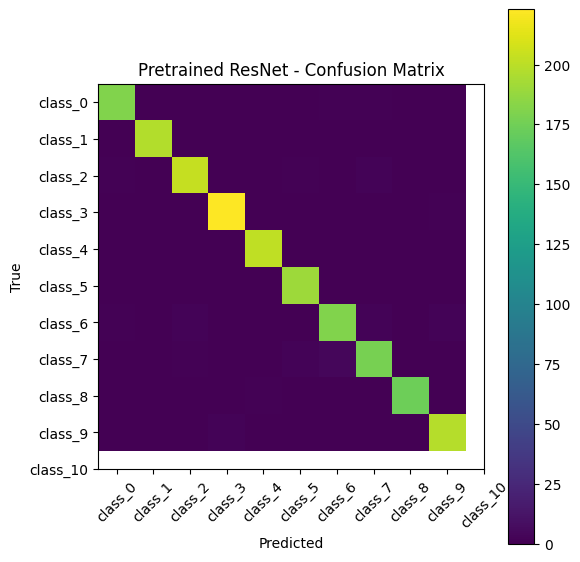

In [ ]:
# === TODO ===
# Evaluate the pretrained model on the test set and:
# - print loss, accuracy, and macro F1
# - build and display its confusion matrix

test_loss_pre, test_acc_pre, test_f1_pre = evaluate(model_pretrained, test_loader, criterion_pre, device)

print(f"[Pretrained] Test Loss: {test_loss_pre:.4f}")
print(f"[Pretrained] Test Acc:  {test_acc_pre:.4f}")
print(f"[Pretrained] Test F1:   {test_f1_pre:.4f}")

# Confusion matrix
model_pretrained.eval()
all_preds_pre = []
all_targets_pre = []

with torch.no_grad():
    for X_batch, y_batch in test_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        logits = model_pretrained(X_batch)
        preds = torch.argmax(logits, dim=1)

        all_preds_pre.extend(preds.cpu().numpy())
        all_targets_pre.extend(y_batch.cpu().numpy())

cm_pre = confusion_matrix(all_targets_pre, all_preds_pre)

plt.figure(figsize=(6,6))
plt.imshow(cm_pre, interpolation="nearest")
plt.title("Pretrained ResNet - Confusion Matrix")
plt.colorbar()
tick_marks = np.arange(num_classes)
plt.xticks(tick_marks, label_names, rotation=45)
plt.yticks(tick_marks, label_names)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.tight_layout()
plt.show()


## 8. Style modification experiment

Create a styled version of the dataset by applying strong style transforms:
- Posterization
- Solarization
- Blur

Then evaluate both models on the styled test set and compare performance.


Elias: this experiment is intended to make our model face new unseen data and test what will its performance be, our styled images are twisted from the scratch initial ones, so if our model keeps giving similar results as to the scratch and pre-trained models, it means it is not performing well (repetitives results, not learning, limited performance)

In [ ]:
import torchvision.transforms as T

image_size = 224
imagenet_mean = [0.485, 0.456, 0.406]
imagenet_std  = [0.229, 0.224, 0.225]

styled_transform = T.Compose([
    T.Resize((image_size, image_size)),
    T.RandomPosterize(bits=4),
    T.RandomSolarize(threshold=128),
    T.GaussianBlur(kernel_size=(5, 9), sigma=(0.1, 5.)),
    T.ToTensor(),
    T.Normalize(mean=imagenet_mean, std=imagenet_std),
])

In [ ]:
# === TODO ===
# Create new Dataset and DataLoader objects for the styled version
# of the test split (and optionally train/val as well).

train_dataset_styled = HFImageDataset(train_hf, image_key, label_key, transform=styled_transform)
val_dataset_styled   = HFImageDataset(val_hf, image_key, label_key, transform=styled_transform)
test_dataset_styled  = HFImageDataset(test_hf, image_key, label_key, transform=styled_transform)

train_loader_styled = DataLoader(train_dataset_styled, batch_size=batch_size, shuffle=True)
val_loader_styled   = DataLoader(val_dataset_styled, batch_size=batch_size, shuffle=False)
test_loader_styled  = DataLoader(test_dataset_styled, batch_size=batch_size, shuffle=False)


In [ ]:
# === TODO ===
# Evaluate both model_scratch and the pretrained model on the styled test loader.
# Print the metrics for comparison with the original test set.

test_loss_scratch_styled, test_acc_scratch_styled, test_f1_scratch_styled = evaluate(model_scratch, test_loader_styled, criterion, device)

print(f"[Scratch CNN, styled] Test Loss: {test_loss_scratch_styled:.4f}")
print(f"[Scratch CNN, styled] Test Acc:  {test_acc_scratch_styled:.4f}")
print(f"[Scratch CNN, styled] Test F1:   {test_f1_scratch_styled:.4f}")

test_loss_pre_styled, test_acc_pre_styled, test_f1_pre_styled = evaluate(model_pretrained, test_loader_styled, criterion_pre, device)

print(f"[Pretrained, styled] Test Loss: {test_loss_pre_styled:.4f}")
print(f"[Pretrained, styled] Test Acc:  {test_acc_pre_styled:.4f}")
print(f"[Pretrained, styled] Test F1:   {test_f1_pre_styled:.4f}")

[Scratch CNN, styled] Test Loss: 1.8627
[Scratch CNN, styled] Test Acc:  0.3764
[Scratch CNN, styled] Test F1:   0.3628
[Pretrained, styled] Test Loss: 0.3652
[Pretrained, styled] Test Acc:  0.8785
[Pretrained, styled] Test F1:   0.8781


## 9. Comparison table and short analysis

Use your metrics to fill in the table below (you can do this in a markdown cell
or externally) and then write a short analysis.

| Model           | Dataset Style | Test Acc | Test Macro F1 | Notes |
|----------------|---------------|----------|---------------|-------|
| Scratch CNN    | Original      |0.6728    |0.6757         |       |
| Pretrained     | Original      |0.9877    |0.9875         |       |
| Scratch CNN    | Styled        |0.3764    |0.3628         |       |
| Pretrained     | Styled        |0.8785    |0.8781         |       |

Consider questions such as:

-1- Which model is more robust to the style changes?

-The **Pretrained ResNet** model is significantly more robust to the style changes than the Scratch CNN. Its performance gracefully degrades compared to the severe drop experienced by the model trained from scratch.


-2- How big is the performance drop for each model?

-   **Scratch CNN:**
    -   Test Accuracy dropped from 0.6728 to 0.3764, a decrease of **0.2964**. (Approx. 44% relative drop)
    -   Test Macro F1 dropped from 0.6757 to 0.3628, a decrease of **0.3129**. (Approx. 46% relative drop)

-   **Pretrained ResNet:**
    -   Test Accuracy dropped from 0.9877 to 0.8785, a decrease of **0.1092**. (Approx. 11% relative drop)
    -   Test Macro F1 dropped from 0.9875 to 0.8781, a decrease of **0.1094**. (Approx. 11% relative drop)

These figures clearly show that the performance drop for the Scratch CNN was much larger, both in absolute and relative terms, indicating its fragility to unseen stylistic variations.


-3- What might explain the difference?

The superior robustness of the pretrained ResNet can be attributed to several factors:

1.  **Pretraining on a Massive, Diverse Dataset (ImageNet):** The ResNet model was initially trained on ImageNet, a dataset comprising millions of images across 1000 categories. This extensive pretraining allows the model to learn a rich hierarchy of features, from simple edges and textures to complex object parts, that are highly generalized and invariant to many variations, including stylistic ones. The features learned are not tied to specific styles but rather represent fundamental visual patterns.

2.  **Transfer Learning Benefit:** By freezing most of its layers and only fine-tuning the final classification head, we effectively leveraged the powerful, general-purpose feature extractor learned during pretraining. These learned features are robust enough to handle the stylistic modifications without drastic performance degradation.

3.  **Limited Training Data for Scratch Model:** The Scratch CNN was trained solely on a smaller subset of images (our Imagenet-10 split) from scratch. With less exposure to diverse image variations during training, it likely learned features that are more specific to the original style of its training data. When presented with the heavily styled images, these learned features are no longer optimal, leading to a significant drop in performance.

4.  **Architectural Depth and Complexity:** Pretrained models like ResNet are typically much deeper and have more parameters than a custom-built scratch CNN. This architectural complexity, combined with large-scale pretraining, allows them to capture more nuanced and robust representations of images.


Your analysis is consistent with the reported metrics and correctly captures the robustness gap between the two models.
One practical takeaway here is how large the relative drop is for the scratch model compared to the pretrained one.
This kind of gap is often the signal used in practice to justify transfer learning as a default choice.

## 10. Can the classifier act as an object detector?

This section contrasts the output of the trained classifiers with the output of a pretrained object-detection model.
All models inspect the same image from the test split.

The purpose is to illustrate the difference between:

- Classification: returning one predicted class for the entire image.

- Detection: locating individual objects and identifying each one.

A classifier has no mechanism to localize or count objects.
A detector produces bounding boxes, object classes, and confidences.

### 10.1 Display the selected test image with its ground-truth label

Ground truth ID: 1
Ground truth label: class_1


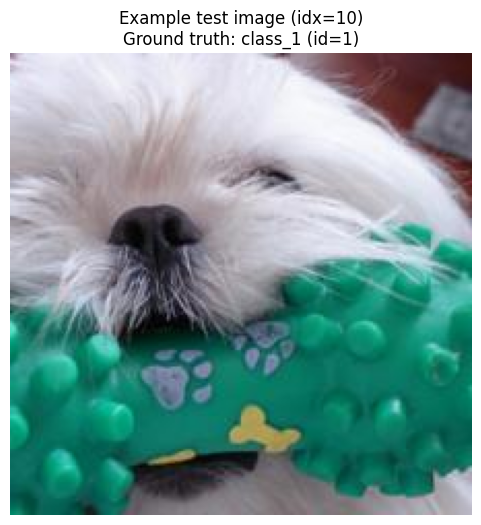

In [ ]:
# Choose a fixed index from test_hf (for example idx_scene = 10).
# Retrieve the image and its label, convert the image to RGB if needed,
# and display it with a title that includes the ground-truth label.

idx_scene = 10

scene_example = test_hf[idx_scene]
scene_img = scene_example[image_key]

# Ground-truth label for this image
true_label_id = scene_example[label_key]
true_label_name = label_names[true_label_id]

print(f"Ground truth ID: {true_label_id}")
print(f"Ground truth label: {true_label_name}")

# Ensure RGB
if isinstance(scene_img, Image.Image) and scene_img.mode != "RGB":
    scene_img = scene_img.convert("RGB")

plt.figure(figsize=(6, 6))
plt.imshow(scene_img)
plt.axis("off")
plt.title(
    f"Example test image (idx={idx_scene})\n"
    f"Ground truth: {true_label_name} (id={true_label_id})"
)
plt.show()



### 10.2 Classifier predictions on the same image

In [ ]:
# Prepare the image for classification
img_tensor = test_transform(scene_img).unsqueeze(0).to(device)

# Scratch CNN Eval
model_scratch.eval()
# Scratch CNN classifier
with torch.no_grad():
    logits_scratch = model_scratch(img_tensor)
    conf_scratch, pred_idx_scratch = torch.max(torch.softmax(logits_scratch, dim=1), dim=1)
    pred_idx_scratch = pred_idx_scratch.item()
    conf_scratch = conf_scratch.item()

print(f"[Scratch CNN] Prediction: class {pred_idx_scratch} "
      f"({label_names[pred_idx_scratch]}), confidence={conf_scratch:.2f}")

# Pretrained ResNet Eval
model_pretrained.eval()

# Pretrained ResNet
with torch.no_grad():
    logits_pre = model_pretrained(img_tensor)
    conf_pre, pred_idx_pre = torch.max(torch.softmax(logits_pre, dim=1), dim=1)
    pred_idx_pre = pred_idx_pre.item()
    conf_pre = conf_pre.item()

print(f"[Pretrained ResNet] Prediction: class {pred_idx_pre} "
      f"({label_names[pred_idx_pre]}), confidence={conf_pre:.2f}")

[Scratch CNN] Prediction: class 4 (class_4), confidence=0.21
[Pretrained ResNet] Prediction: class 1 (class_1), confidence=1.00


### 10.3 YOLO detections on the same image

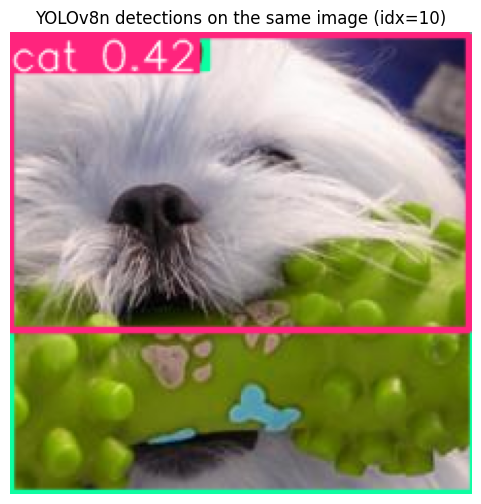

Detected class indices: [15.0, 59.0]
Detected confidences:   [0.415839284658432, 0.28730547428131104]


In [ ]:
from ultralytics import YOLO

# === TODO ===
# Use a pretrained YOLO model (e.g. yolov8n from ultralytics) to detect objects
# in the same image. Display the image with bounding boxes and print the
# detected classes and confidences.

detector = YOLO("yolov8n.pt")

results = detector.predict(scene_img, conf=0.25, verbose=False)
detected = results[0]

# Plot detections
det_img = detected.plot()  # numpy array with boxes and labels
plt.figure(figsize=(6, 6))
plt.imshow(det_img)
plt.axis("off")
plt.title(f"YOLOv8n detections on the same image (idx={idx_scene})")
plt.show()

print("Detected class indices:", detected.boxes.cls.tolist())
print("Detected confidences:  ", [float(c) for c in detected.boxes.conf])

### 10.4 Interpretation: why the classifier cannot act as a detector

Answer the following:

1. When the scratch CNN and pretrained ResNet are applied to this image, how many outputs do they produce?
Do these outputs contain any spatial information about objects?

-When both the scratch CNN and the pretrained ResNet are applied to an image, they each produce 11 outputs. These outputs are logits, which are raw scores for each of the 11 possible classes. After applying a softmax function, these logits can be interpreted as probabilities for each class. These outputs do not contain any spatial information about objects within the image. They provide a single prediction for the entire image, indicating which class the model believes the whole image belongs to.



2. When YOLO is applied to the same image, what type of information does it provide?
How many detections appear, and what does each detection contain?

-When YOLO is applied to the same image, it provides object detections, which means it identifies specific objects within the image, their locations, their predicted classes, and a confidence score for each detection. Unlike classifiers, YOLO provides spatial information in the form of bounding boxes around each detected object.

From the output of the YOLO model on this specific image, there are two detections:

Detection 1: A bounding box around an object, predicted to be class 15, with a confidence of approximately 0.416.
Detection 2: A bounding box around another object, predicted to be class 59, with a confidence of approximately 0.287.
Each detection contains:

Bounding box coordinates: The pixel location and size of the detected object within the image.
Predicted class: An identifier for the type of object detected (e.g., 'person', 'car', 'bottle'). YOLO models are typically trained on large datasets like COCO, which have many more classes than just the 11 from ImageNet-10, so class 15 and 59 refer to specific objects within the YOLO's class set.
Confidence score: A probability that indicates how confident the model is about the presence and classification of that specific object.



3. Why is a classifier expected to perform poorly at object detection, even when it sometimes predicts a class that seems related to the scene?

-A classifier is fundamentally designed to answer the question, "What is in this image?" by assigning a single label to the entire image. Object detection, on the other hand, aims to answer, "Where are the objects, what are they, and how many are there?"

Here's why a classifier is expected to perform poorly at object detection:

Lack of Spatial Localization: Classifiers are trained to recognize patterns across the entire image and output a single class prediction. Their architectures (e.g., global pooling layers) intentionally discard precise spatial information needed to draw bounding boxes around specific objects. They learn that certain pixel arrangements correlate with a class, but not where those arrangements are.

Single Output vs. Multiple Outputs: A classifier produces one probability distribution over classes for the whole image. If an image contains multiple objects of different classes (e.g., a dog and a cat), it can only output the most dominant class or an aggregate prediction. It cannot identify both objects separately.

Inability to Count: Since a classifier outputs only a single label for the entire image, it cannot count multiple instances of the same object. If there are five bottles in an image, a classifier will still only predict "bottle" once, or perhaps a related class, but it won't tell you there are five.

Training Data: Classifiers are trained on images where each image is associated with a single ground-truth label. Object detectors are trained on images with detailed annotations for every object, including their class and precise bounding box coordinates.

"Related but not precise" Predictions: When a classifier predicts a class "related to the scene," it means its global patterns matched well enough to suggest the presence of something relevant. For example, if an image contains a car, a classifier might correctly say "car." However, it won't tell you where the car is within the image, or if there are multiple cars. It's making a high-level judgment about the image content, not a granular, localized one.

In essence, classifiers are like a person who can tell you if a photo is of a "crowded city street" but can't point out specific people or cars within that street. Object detectors are trained to do that pointing.


Your explanation accurately reflects the behavior seen in the classifier outputs and the YOLO detections.
A useful practical insight is that the difference becomes obvious only when you visualize both outputs on the same image.
This is why qualitative inspection is commonly used alongside metrics in vision tasks.